In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

In [26]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
c = 3e8 # m/s
lambda_ = 1.55*um
f_ = c/lambda_

## Parametros do guia de onda

neff = 2.445
ng = 4.248

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

### Anel *all-pass* ###

In [27]:
def phi(lambda_, L, n_eff=neff):
    num = 2*pi*n_eff*L
    den = lambda_
    return num/den

def t(phi, r, a):
    num = r - a*np.exp(-1j*phi)
    den = 1 - r*a*np.exp(-1j*phi)
    return num/den

def Tn(phi, r, a):
    num = r**2 - 2*r*a*np.cos(phi) + a**2
    den = 1 - 2*r*a*np.cos(phi) + (r*a)**2
    return num/den

def t_N(phi, N, r, a):
    kappa2 = 1 - r**2
    A = kappa2*a*np.exp(-1j*phi)
    sum = 0
    for n in range(0,N,1):
        a_n = np.power(r*a*np.exp(-1j*phi), n)
        sum += a_n
    return r - A*sum

### Anel *add-drop* ###

In [28]:
def T_p(phi,r1,r2,a):
    num = r1**2 - 2*r1*r2*a*np.cos(phi) + (r2*a)**2
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

def T_d(phi,r1,r2,a):
    num = (1 - r1**2)*(1 - r2**2)*a
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

# Questões #

1) **Soma de voltas**. Para $r=a=0,99$, quantas voltas são necessárias para o mínimo de transmissão chegar a $1\,%$ do valor final? Relacione com a finesse;

2) **Regimes pela fase**. Para $a=0,95$, trace $\arg{t}$ com $r=0,90\,;\,0,95\,;\,0,99$ e classifiique cada caso;

3) ***Add-drop* assimétrico**. Verifique que $T_p=0$ quando $r_1=r_2a$. Qual o destino da energia do sinal óptico não direcionada à porta drop?

4) **Extração de parâmetros**. A partir de $FSR$, $FWHM$ e $ER$ de um *all-pass*, obtenha $ra$ e os dois pares $\{r,a\}$ possíveis;

5) **Projeto**. REfaça o exemplo para $FSR=20\,nm$ e $Q=5000$. O $L_c$ resultante é viável?

### Respostas da 1 ###

Número de voltas: 115;

$F/2\pi = 25$ voltas.

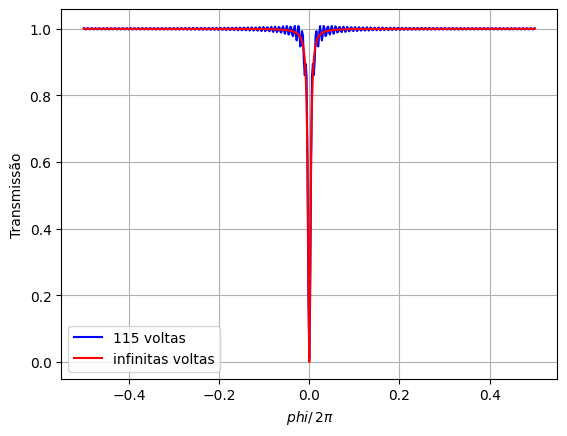

In [56]:
r = 0.99
a = 0.99

phi_array = np.linspace(-pi,pi,501)
N = 115

tN = t_N(phi_array, N, r, a)
tn_N = np.abs(tN)**2

Tn_array = Tn(phi_array, r, a)

plt.plot(phi_array/(2*pi), tn_N, color = 'blue', label = '%d voltas'%N)
plt.plot(phi_array/(2*pi), Tn_array, color = 'red', label = 'infinitas voltas')
plt.grid(True)
plt.legend(loc = 'best')
plt.xlabel(r'$\,phi/\,2\pi$')
plt.ylabel('Transmissão')
plt.show()

## Respostas da 2 ##

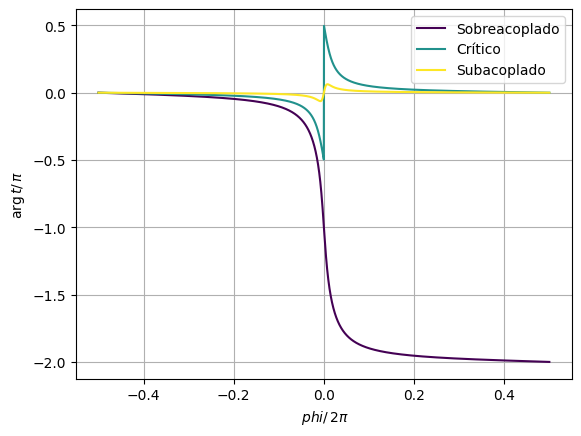

In [62]:
a = 0.95
r_array = [0.90, 0.95, 0.99]

phi_array = np.linspace(-pi,pi,5001)

k = 0

for r in r_array:   

    tn_array = t(phi_array, r, a)
    phase_array = np.angle(tn_array)

    if r < a:
        label = 'Sobreacoplado'
        phase_array = np.where(phase_array<0, phase_array, phase_array-2*pi)
    elif r == a:
        label = 'Crítico'
    else:
        label = 'Subacoplado'

    plt.plot(phi_array/(2*pi), phase_array/(pi), color=cmap1(k/(len(r_array)-1)), label = label)
    k += 1

plt.grid(True)
plt.legend(loc = 'best')
plt.xlabel(r'$\,phi/\,2\pi$')
plt.ylabel(r'$\arg{t}/\,\pi$')
plt.show()

### Resposta da 3 ###

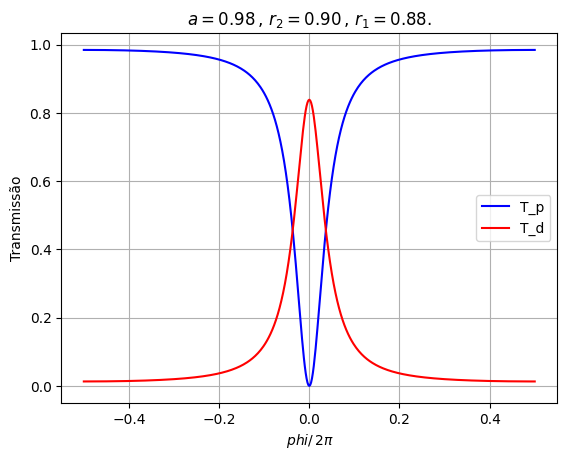

In [75]:
a = 0.98
r2 = 0.9
r1 = r2*a

phi_array = np.linspace(-pi,pi,501)

Tp_array = T_p(phi_array, r1, r2, a)
Td_array = T_d(phi_array, r1, r2, a)

plt.plot(phi_array/(2*pi), Tp_array, color = 'blue', label = 'T_p')
plt.plot(phi_array/(2*pi), Td_array, color = 'red', label = 'T_d')
plt.grid(True)
plt.legend(loc = 'best')
plt.xlabel(r'$\,phi/\,2\pi$')
plt.ylabel('Transmissão')
plt.title(r'$a=%.2f\,,\,r_2=%.2f\,,\,r_1=%.2f$.' %(a,r2,r1))
plt.show()

### Resposta da 4 ###

$$A=\frac{FSR}{\pi FWHM}\,;$$
$$ra=\frac{2A^2+1+\sqrt{4A^2+1}}{2A^2}=B\,;$$
$$C = \frac{(1-B)^2}{(1+B^2)}\,;$$

Os dois pares, $\{r_1,a_1\}$ e $\{r_2,a_2\}$ são:

$$r_1=\sqrt{\frac{B\left(1+\frac{C}{ER}\right)+2B\sqrt{\frac{C}{ER}}}{1-\frac{C}{ER}}}\,,\,a_1=\frac{B}{r_1}\,;$$
$$r_1=\sqrt{\frac{B\left(1+\frac{C}{ER}\right)-2B\sqrt{\frac{C}{ER}}}{1-\frac{C}{ER}}}\,,\,a_2=\frac{B}{r_2}\,.$$

### Resposta da 5 ###

$L=25,94\,\mu m$;

$r=0,976$;

$L_c = 0,995\mu m$. Não é necessário $L_c$

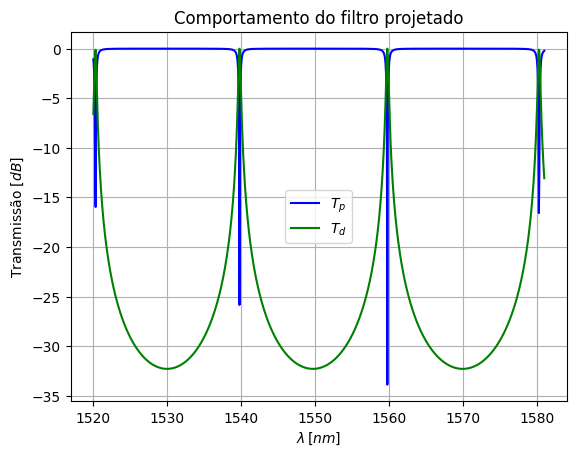

In [50]:
a = 1
r = 0.976
L = 25.94*um
n_eff = 4.63 #4.601
lambda_array = np.linspace(1520,1581,1001)*nm

phi_array = phi(lambda_array, L, n_eff)
Tp_array = T_p(phi_array, r, r, a)
Td_array = T_d(phi_array, r, r, a)

Tp_dB_array = 10*np.log10(Tp_array)
Td_dB_array = 10*np.log10(Td_array)

plt.plot(lambda_array/nm, Tp_dB_array, color = 'blue', label = '$T_p$')
plt.plot(lambda_array/nm, Td_dB_array, color = 'green', label = r'$T_d$')
plt.grid(True)
plt.xlabel(r'$\lambda\,[nm]$')
plt.ylabel(r'Transmissão [$dB$]')
plt.legend(loc = 'best')
plt.title('Comportamento do filtro projetado')
#plt.xlim([1520,1580])
plt.show()